Note: you may need to restart the kernel to use updated packages.
Bayesian Network Structure:
DiscreteBayesianNetwork with 5 nodes and 4 edges


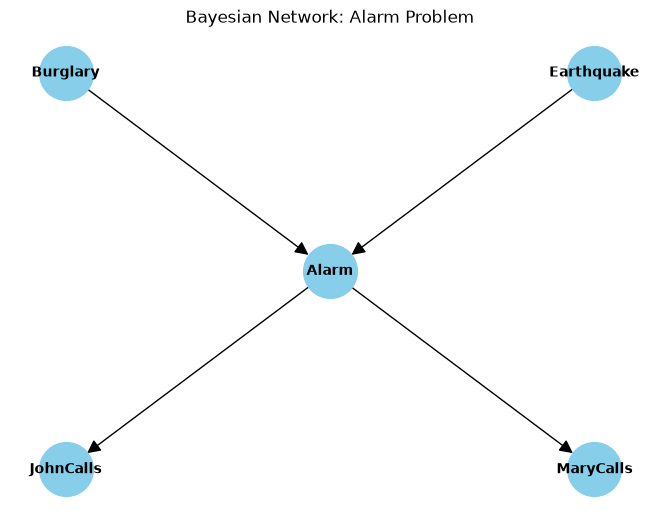

100%|██████████| 9999/9999 [00:07<00:00, 1252.28it/s]


Approximate Probabilities of Burglary:
Burglary
0    1.0
Name: proportion, dtype: float64


In [3]:
%pip install pgmpy

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.sampling import GibbsSampling
import networkx as nx
import matplotlib.pyplot as plt

# Define the Bayesian network structure
network = DiscreteBayesianNetwork([
    ('Burglary', 'Alarm'),
    ('Earthquake', 'Alarm'),
    ('Alarm', 'JohnCalls'),
    ('Alarm', 'MaryCalls')
])

# Define the Conditional Probability Distributions (CPDs)
cpd_burglary = TabularCPD(
    variable='Burglary',
    variable_card=2,
    values=[[0.999], [0.001]]
)

cpd_earthquake = TabularCPD(
    variable='Earthquake',
    variable_card=2,
    values=[[0.998], [0.002]]
)

cpd_alarm = TabularCPD(
    variable='Alarm',
    variable_card=2,
    values=[
        [0.999, 0.71, 0.06, 0.05],
        [0.001, 0.29, 0.94, 0.95]
    ],
    evidence=['Burglary', 'Earthquake'],
    evidence_card=[2, 2]
)

cpd_john_calls = TabularCPD(
    variable='JohnCalls',
    variable_card=2,
    values=[
        [0.95, 0.1],
        [0.05, 0.9]
    ],
    evidence=['Alarm'],
    evidence_card=[2]
)

cpd_mary_calls = TabularCPD(
    variable='MaryCalls',
    variable_card=2,
    values=[
        [0.99, 0.3],
        [0.01, 0.7]
    ],
    evidence=['Alarm'],
    evidence_card=[2]
)

# Add CPDs to the network
network.add_cpds(
    cpd_burglary,
    cpd_earthquake,
    cpd_alarm,
    cpd_john_calls,
    cpd_mary_calls
)

# Print the Bayesian network structure
print("Bayesian Network Structure:")
print(network)

# Create a directed graph using networkx
G = nx.DiGraph()

# Define nodes and edges
nodes = ['Burglary', 'Earthquake', 'Alarm', 'JohnCalls', 'MaryCalls']

edges = [
    ('Burglary', 'Alarm'),
    ('Earthquake', 'Alarm'),
    ('Alarm', 'JohnCalls'),
    ('Alarm', 'MaryCalls')
]

# Add nodes and edges
G.add_nodes_from(nodes)
G.add_edges_from(edges)

# Set positions for nodes
pos = {
    'Burglary': (0, 0),
    'Earthquake': (2, 0),
    'Alarm': (1, -2),
    'JohnCalls': (0, -4),
    'MaryCalls': (2, -4)
}

# Draw the graph
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1500,
    node_color='skyblue',
    font_size=10,
    font_weight='bold',
    arrowsize=20
)

plt.title("Bayesian Network: Alarm Problem")
plt.show()

# Initialize Gibbs Sampling
gibbs_sampler = GibbsSampling(network)

# Number of samples
num_samples = 10000

# Perform sampling (GibbsSampling in pgmpy 1.1.2 returns a DataFrame)
samples = gibbs_sampler.sample(size=num_samples)

# Query variable
query_variable = "Burglary"

# Approximate probability (states are shown in ascending order)
query_result = samples[query_variable].value_counts(normalize=True).sort_index()

# Print result
print(f"\nApproximate Probabilities of {query_variable}:")
print(query_result)